# LangChain 1.2 概述


## 这篇笔记先回答什么？

LangChain 不是一个单独的“大模型”，而是连接模型与应用的开发框架。它把模型调用、消息、工具、检索、记忆和 Agent 等能力组织成可以组合的组件。

本篇按照课程第 01 章整理：先说明为什么需要 LangChain，再认识 LangChain 1.x 的定位和模块，接着准备 Python 环境，最后用 RAG、Agent 和技术选型把应用开发路线串起来。

课程示例以 **LangChain 1.2** 为背景。版本、模型供应商和依赖包会继续变化；下面的命令用于理解课程结构，实际安装时应以项目锁定文件和官方文档为准。


## 1. 为什么需要 LangChain？

### 从传统应用走向智能体应用

传统应用通常由人预先写好流程：输入经过固定规则，调用固定接口，返回固定结果。大模型带来了自然语言理解和生成能力，但单独一个模型仍然只是一个推理组件，不能自动访问最新业务数据、调用企业 API，也不会天然保存跨轮上下文。

要做成真正可用的应用，需要把大模型放进一个更大的系统：模型负责理解和决策，应用负责提供数据、工具、记忆和执行边界。

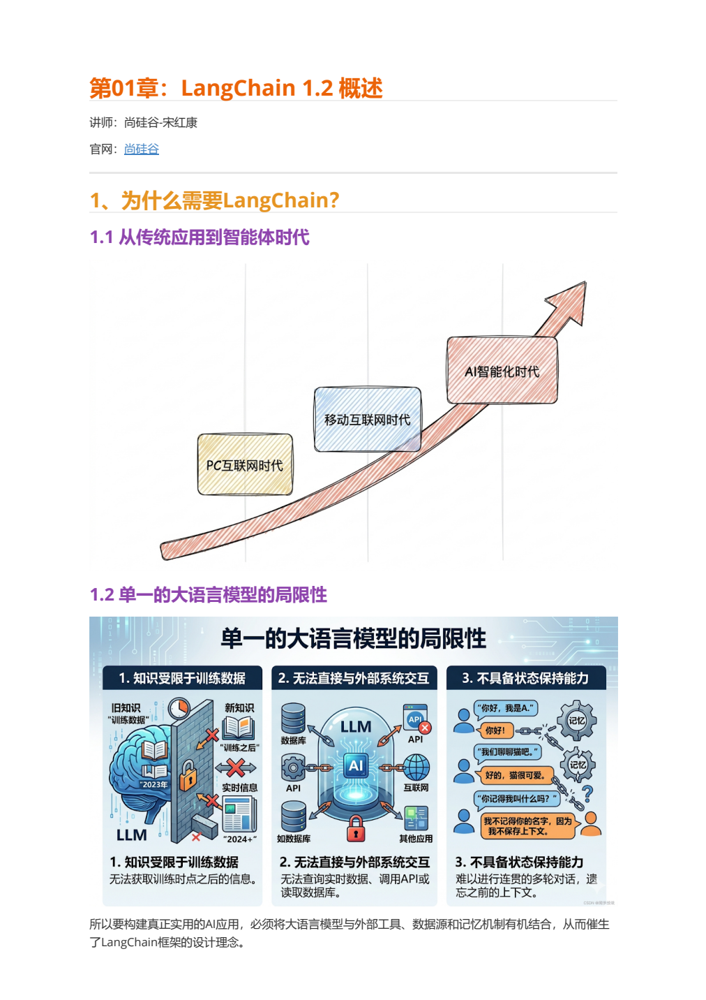


### 单一大语言模型的三个限制

| 限制 | 具体表现 | 应用需要补上的能力 |
| --- | --- | --- |
| 知识受训练数据限制 | 不知道训练截止时间之后的新闻、业务数据和内部文档 | 检索、数据库和实时 API |
| 不能直接与外部系统交互 | 不能自己查询订单、调用天气接口或写入系统 | 工具调用和权限控制 |
| 不会自动保持应用状态 | 多轮交互可能丢失上下文，也不知道用户偏好 | 消息历史、短期记忆和长期记忆 |

因此，LangChain 的设计目标不是替代模型，而是把模型和外部资源连接起来，并封装提示词、消息、工具、检索和 Agent 的组合逻辑。

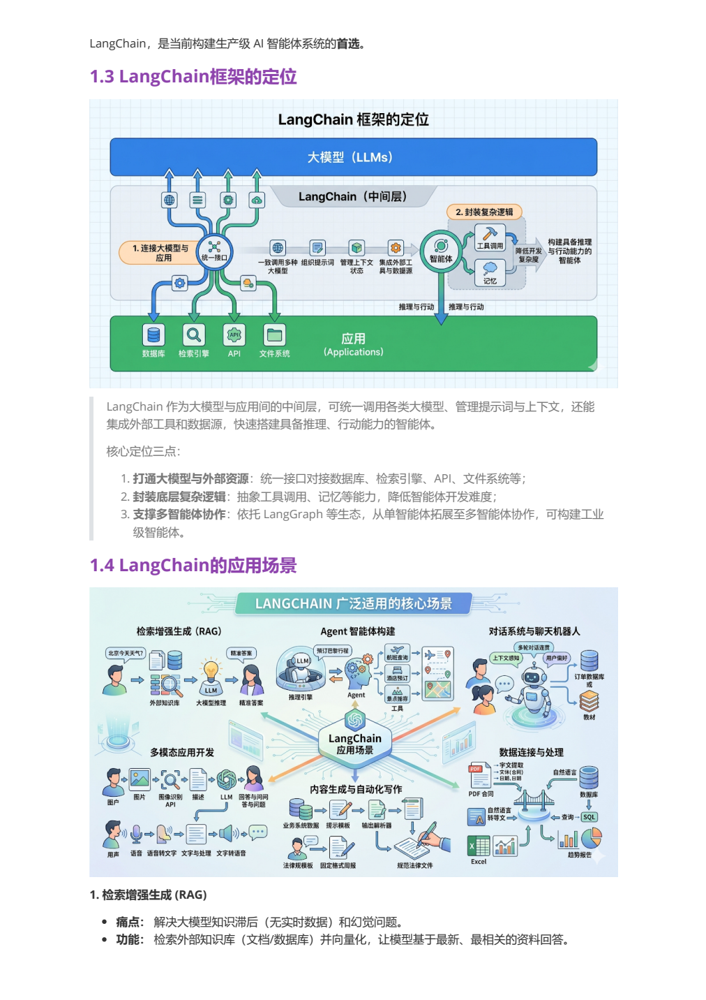


### LangChain 常见应用场景

课程把应用场景归纳为六类：

1. **检索增强生成（RAG）**：先从文档或数据库找到相关资料，再让模型基于资料回答。
2. **Agent 智能体**：让模型根据任务自主选择工具和下一步动作。
3. **对话系统**：维护消息历史、用户偏好和业务上下文。
4. **多模态应用**：结合图像、语音、文本等输入输出。
5. **自动化写作与格式化生成**：用提示词模板和结构化输出生成报告、合同或邮件。
6. **数据连接与结构化处理**：从 PDF、Excel 等资料中提取信息，或把自然语言转换为 SQL。

这些场景的共同点是：模型只是能力中心，应用还需要数据连接、流程控制和结果约束。


## 2. LangChain 是什么？

LangChain 是大模型与应用之间的中间层。它提供统一的模型抽象和可组合组件，让开发者用相近的方式连接不同模型、消息、工具、数据源和 Agent。

可以把它理解成一个面向大模型应用的工具箱：先掌握核心抽象，遇到具体供应商或业务需求时，再按需查对应集成包和 API。

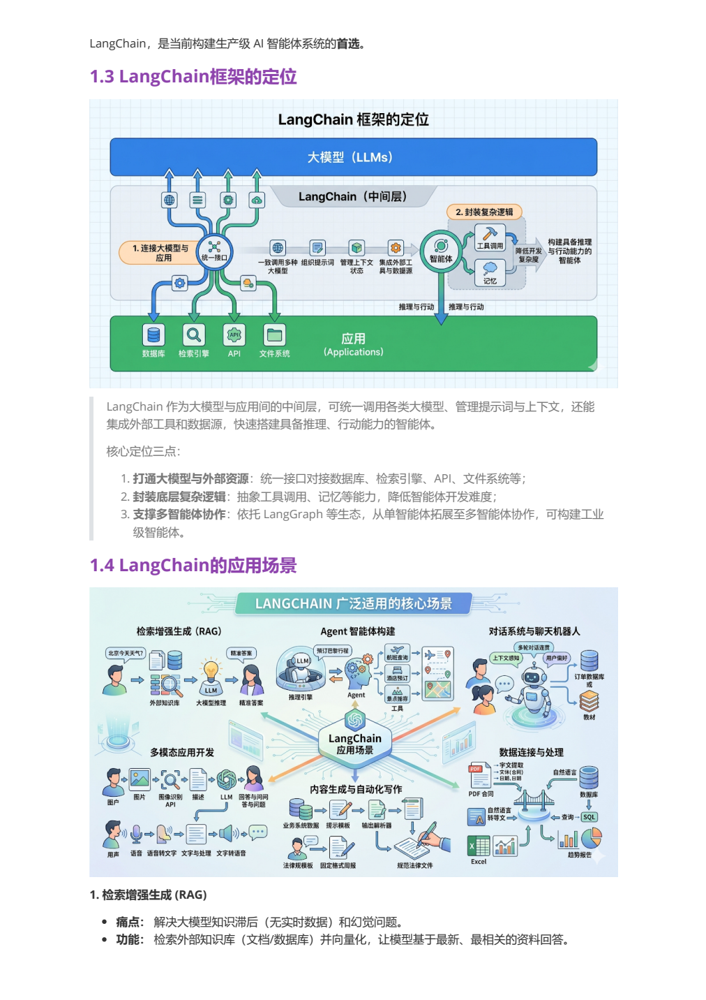


### LangChain 的三项核心价值

**1. 连接模型与外部资源**

通过统一接口连接模型服务、数据库、检索引擎、API 和文件系统，减少应用代码对某一个供应商 SDK 的绑定。

**2. 封装大模型应用的复杂逻辑**

消息、提示词模板、工具调用、记忆和输出解析器可以单独使用，也可以组合成完整流程。

**3. 支持从单 Agent 到复杂协作**

简单应用可以直接使用 LangChain 的 Agent 能力；需要显式状态、分支、循环、持久化或多 Agent 协作时，可以和 LangGraph 配合。


## 3. LangChain 的版本与包结构

### v0.3 与 v1.2 的定位差异

课程将 v0.3 看作以 Chain 为中心的过渡版本，将 v1.x 看作面向生产 Agent 的稳定版本。学习新项目时，优先理解 v1.x 的入口和模块；维护旧项目时，再根据项目锁定版本查阅 classic API。

| 维度 | LangChain v0.3 | LangChain v1.2 |
| --- | --- | --- |
| 核心范式 | Chain 和旧式 AgentExecutor | Agent 与 LangGraph 运行时 |
| Agent 入口 | 常见旧 API，如 `initialize_agent` | 课程推荐 `create_agent` |
| 工具与结构化输出 | 需要较多手动解析 | 更强调类型化工具和结构化输出 |
| 包组织 | 功能集中，依赖较重 | 核心包轻量，集成按供应商拆分 |
| 适用项目 | 维护已有 v0.3 项目 | 新项目和课程学习 |

版本号是课程资料中的背景信息；实际使用时应以项目的 `requirements.txt`、锁定文件和当前文档为准。

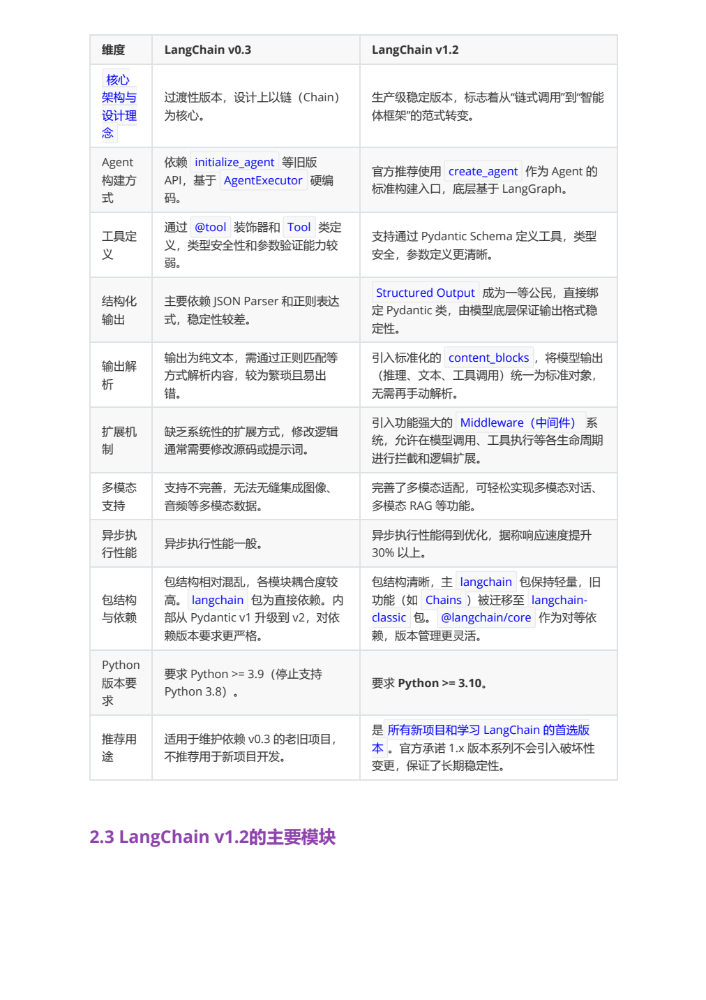


### v1.x 的主要模块

| 包 | 主要职责 | 什么时候会用到 |
| --- | --- | --- |
| `langchain-core` | Runnable、消息、提示词、工具等核心抽象 | 几乎所有 LangChain 应用 |
| `langchain` | 面向应用的高层入口和 Agent 能力 | 快速构建模型应用或 Agent |
| `langchain-community` | 社区和第三方集成 | 需要特定数据库、加载器或工具时 |
| `langchain-classic` | 旧式 Chain 等兼容代码 | 迁移或维护旧项目 |
| `langgraph` | 有状态图、循环、持久化和复杂编排 | 需要可控工作流或多 Agent 协作时 |
| 供应商包 | 如 `langchain-openai`、`langchain-anthropic` | 连接具体模型服务时 |

包拆分的好处是核心保持轻量，模型和工具集成按需安装，不必让每个项目都携带全部依赖。

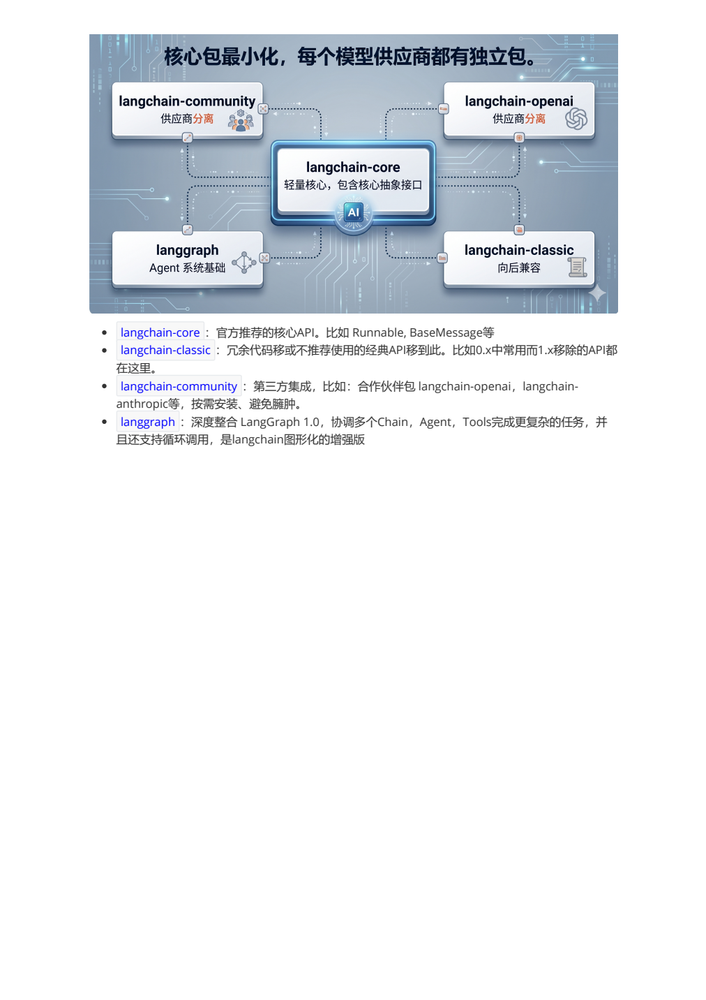


### API 文档与学习方式

常用入口：

- 官方文档：[https://docs.langchain.com/](https://docs.langchain.com/)
- Python API 参考：[https://reference.langchain.com/python/langchain/](https://reference.langchain.com/python/langchain/)
- GitHub：[https://github.com/langchain-ai](https://github.com/langchain-ai)

不要把目标设成背完所有 API。先理解模型、消息、提示词、工具、Agent、Retriever 和 Runnable 的关系；具体集成用到什么，再查什么。


## 4. LangChain 生态的四个支柱

课程把 LangChain 生态分成四层，它们不是互相排斥的替代品，而是可以组合使用的不同职责：

| 支柱 | 负责什么 | 适合回答的问题 |
| --- | --- | --- |
| **LangChain** | 模型、消息、工具、Agent 等基础能力 | 应用“有什么能力”？ |
| **LangGraph** | 状态、节点、边、循环和持久化 | 应用“怎样运行和控制”？ |
| **Deep Agent** | 规划、文件系统、子 Agent 等更高层 Agent 能力 | 怎样减少复杂 Agent 的手工编排？ |
| **LangSmith** | 追踪、调试、评测和监控 | 应用运行得怎样，问题在哪里？ |

一个常见路线是：先用 LangChain 验证能力，再用 LangGraph 增加流程控制，必要时用更高层 Agent 抽象，最后用 LangSmith 做观测和评测。

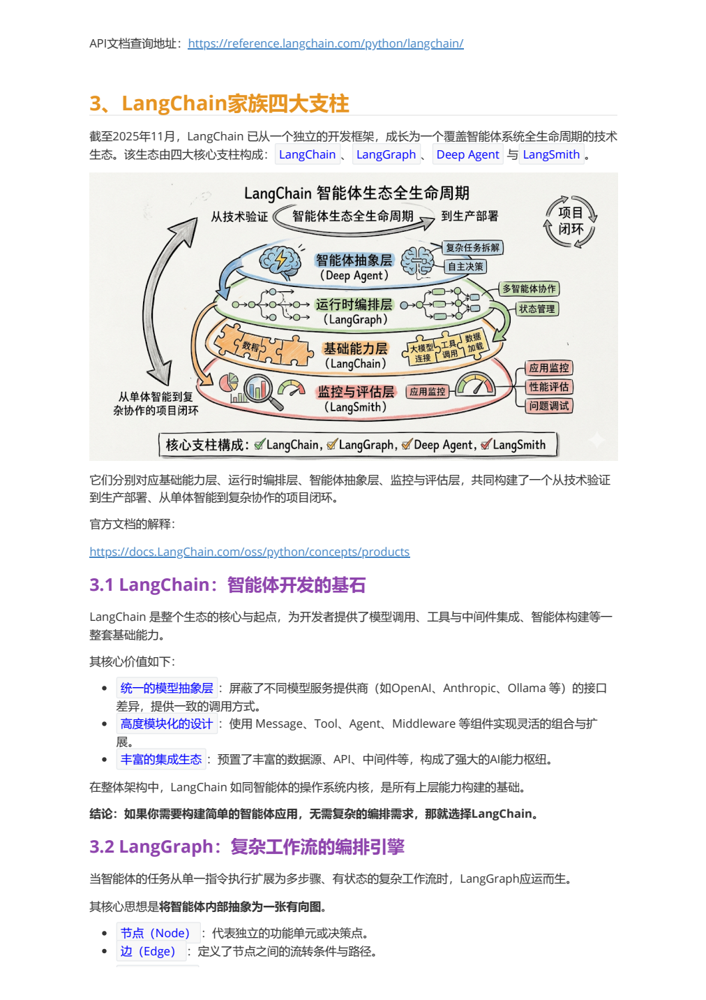


### LangChain、LangGraph 与 Deep Agent 的关系

**LangChain = 能力抽象层**：统一 LLM、Tool、Message 等组件，解决“有什么能力”。

**LangGraph = 执行与编排层**：用 State、Node、Edge 组织分支、循环、并行和持久化，解决“怎么跑”。

**Deep Agent = 更高层的 Agent 执行框架**：在 LangChain 与 LangGraph 之上提供规划、虚拟文件系统和子 Agent 等能力，减少从零实现复杂控制逻辑的工作。

**LangSmith = 观测与评测层**：记录模型调用、提示词、工具、延迟和结果，帮助调试和量化质量。

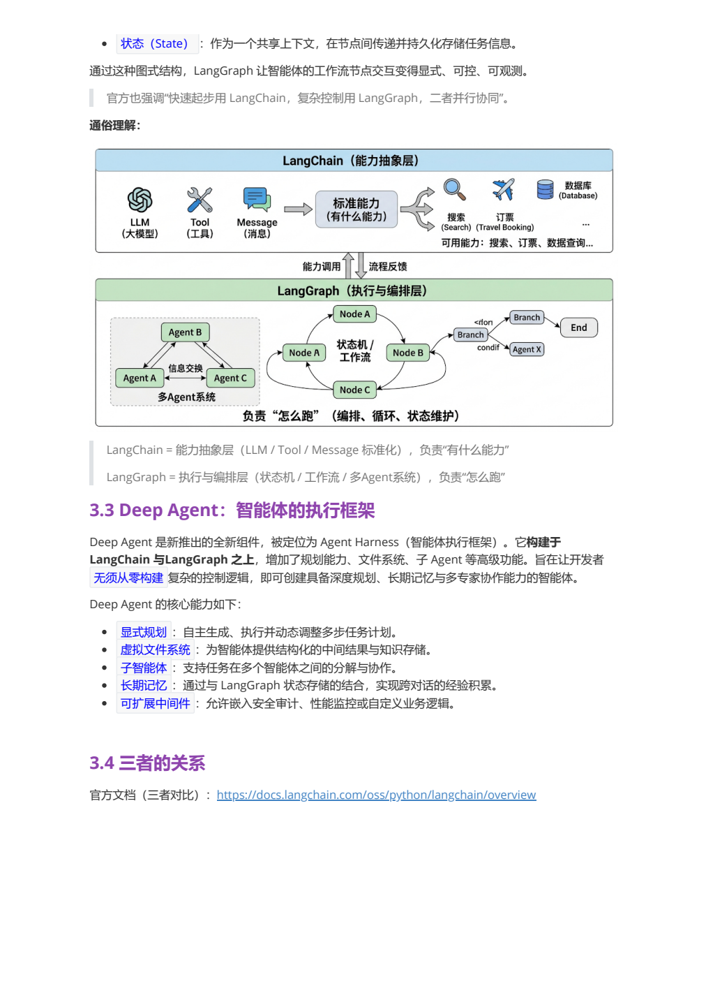


## 5. 开发前的准备

### 需要的基础知识

学习 LangChain 前，至少应熟悉：

- Python 变量、流程控制、函数、类、装饰器、异常和模块导入；
- 列表、字典、JSON，以及同步和异步调用的基本概念；
- LLM、Token、Prompt、Embedding 的基本含义；
- 至少使用过一种模型服务，例如 OpenAI、DeepSeek、通义或 Ollama。

LangChain 同时支持 Python 和 JavaScript/TypeScript。课程使用 Python，因为 Python 版本通常更适合快速验证 AI 应用。


### 为什么要使用虚拟环境？

虚拟环境为每个项目隔离 Python 解释器和依赖包。这样，LangChain 项目的升级不会随意影响其他项目。

| 工具 | Python 解释器 | Python 包 | 非 Python 依赖 | 适合场景 |
| --- | --- | --- | --- | --- |
| `conda` | 可以管理 | 可以管理 | 可以管理 | 深度学习、CUDA、复杂底层依赖 |
| `uv` | 可以创建/管理 | 可以管理 | 不负责 | 纯 Python 项目、Web、Agent、RAG 应用层 |
| `venv` | 基于已有解释器 | 可以管理 | 不负责 | 简单项目和教学演示 |

课程选择 conda；如果项目只是普通 Python 应用，也可以选择 uv 或 venv。


### 用 conda 创建课程环境

下面是课程使用的环境示例。版本号应和项目依赖文件保持一致，不要在同一个环境里随意混装不同大版本。

~~~bash
# 创建并指定 Python 版本
conda create --name langchain1.2 python=3.13.12

# 查看环境
conda env list

# 初始化 conda（首次使用时执行）
conda init

# 激活环境
conda activate langchain1.2

# 验证解释器
python --version
~~~

退出和删除环境：

~~~bash
conda deactivate
conda remove --name langchain1.2 --all
~~~


### 安装 LangChain

课程建议显式指定版本。可以使用 conda：

~~~bash
conda install langchain==1.2.12
conda list
~~~

也可以使用 pip：

~~~bash
pip install langchain==1.2.12
pip list
~~~

如果项目提供了 `requirements.txt`，优先按项目文件安装，而不是只安装一个 `langchain` 包。模型供应商和数据库等集成通常还需要单独安装对应的合作伙伴包。


### 验证安装是否成功

安装后只检查版本，不在笔记中执行代码：

~~~python
import langchain

print(langchain.__version__)
~~~

如果项目使用的是较新的包结构，版本信息也可以通过包管理器查看：

~~~bash
pip show langchain
~~~

排查问题时先确认三件事：当前终端是否激活了正确环境、`python` 和 `pip` 是否属于同一环境、项目是否锁定了兼容版本。


## 6. RAG：给模型补充外部知识

### 为什么需要 RAG？

大模型存在两个常见问题：训练知识会冻结，无法自动知道最新信息；面对训练数据中没有的专业内容时，可能生成听起来合理但没有依据的答案。

RAG 是 **Retrieval-Augmented Generation（检索增强生成）**。它先从外部知识库检索相关内容，再把检索结果作为上下文交给模型生成答案。模型不需要重新训练，就能在回答时参考企业文档、产品手册或最新资料。

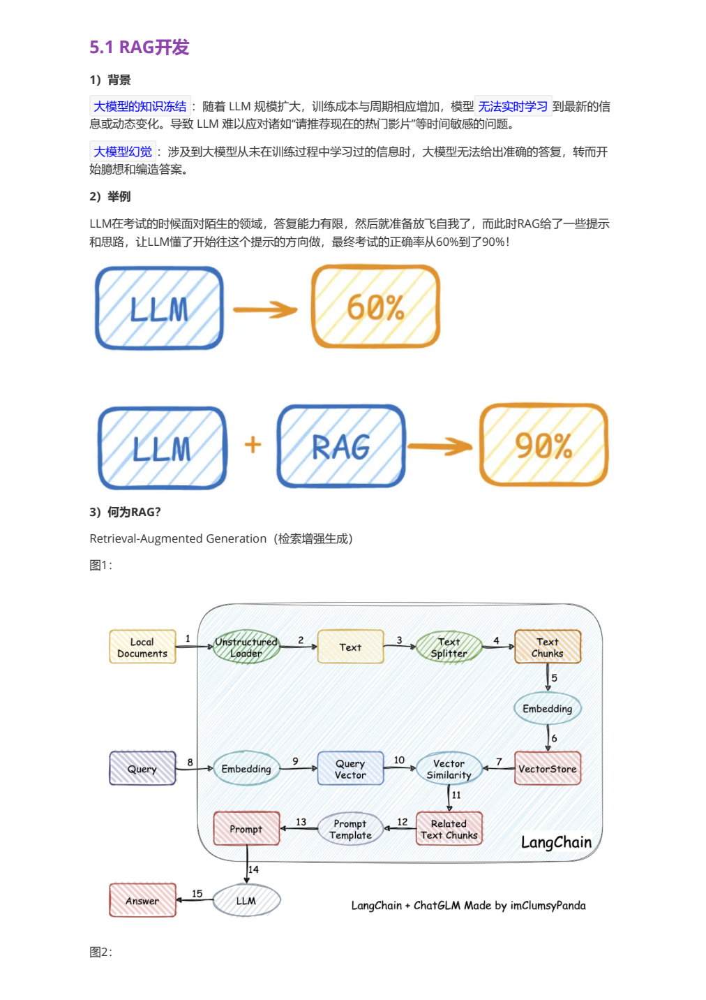


### RAG 的离线建库与在线问答

**离线建库**：

~~~text
原始文件
  → 文件解析
  → 文本切分（Text Chunks）
  → 向量化（Embeddings）
  → 存储与索引（Vector Store）
~~~

**在线问答**：

~~~text
用户问题
  → 问题向量化
  → 向量数据库相似度搜索
  → 取回相关文本块
  → 将 Context + User Query 放进 Prompt
  → LLM 生成答案
~~~

可以把 `Prompt` 简化理解为：

~~~text
Prompt = 检索到的上下文 Context + 用户问题 User Query
~~~

RAG 的关键不是“把所有文件塞给模型”，而是先把资料处理成可检索的知识片段，再只取和问题相关的内容。

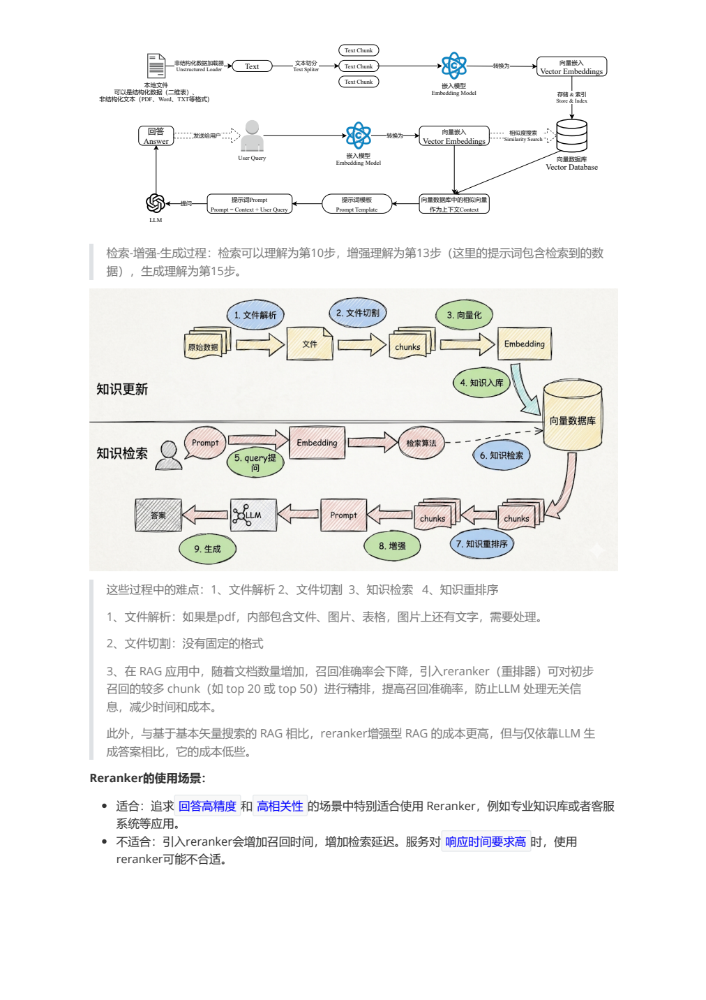


### RAG 的四个难点

1. **文件解析**：PDF 可能同时包含正文、图片、表格和图片中的文字。
2. **文件切分**：不同文档没有统一格式，切得太短会丢上下文，切得太长会降低检索精度并浪费上下文窗口。
3. **知识检索**：向量相似不一定等于业务相关，需要选择合适的 Embedding、切分策略和召回数量。
4. **知识重排序**：先召回较多文本块，再用 Reranker 按问题相关性重新排序，通常能提高精度，但会增加延迟和成本。

Reranker 更适合专业知识库、客服和高准确率场景；对延迟特别敏感的服务，需要权衡额外排序带来的收益。


## 7. Agent：让模型参与规划和行动

### Agent 的基本公式

Agent 不只是“调用一次模型”。它让模型根据目标和当前状态进行规划，选择工具，读取工具结果，再决定下一步动作。

~~~text
Agent = LLM + Planning + Tools + Memory + Action
~~~

例如“安排一次西藏旅行”：模型负责理解目标和规划步骤，工具负责查路线、订交通和酒店，记忆负责保留预算与偏好，Action 负责真正提交操作。

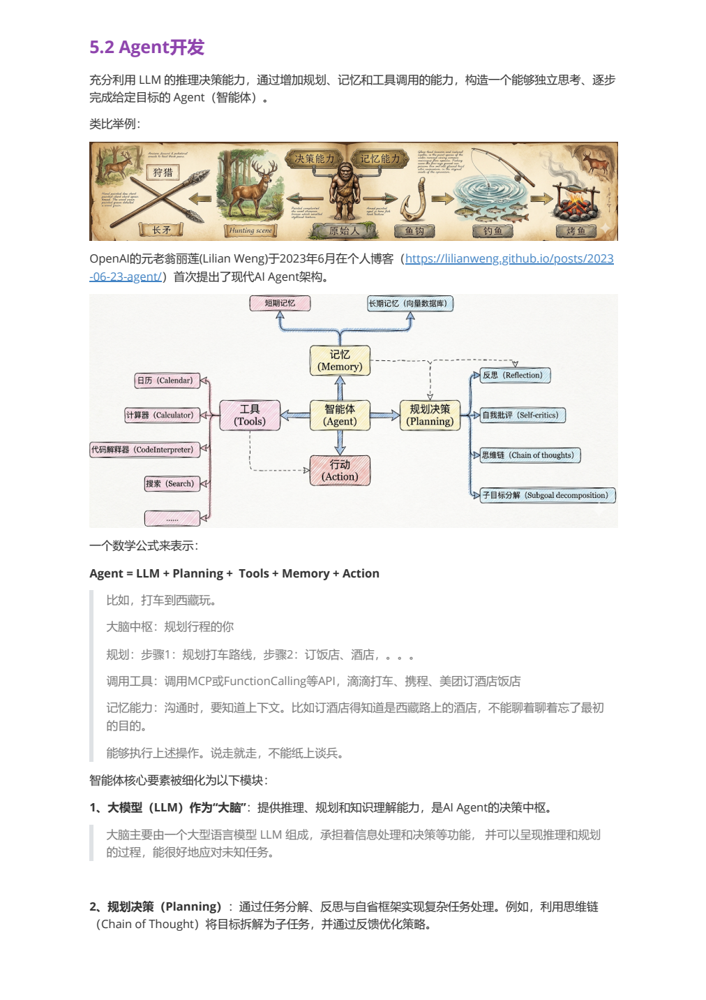


### Agent 的五个核心模块

| 模块 | 作用 | 示例 |
| --- | --- | --- |
| LLM | 理解任务、推理和决策 | 判断先查天气还是先查路线 |
| Planning | 拆分任务、反思和调整策略 | 把旅行拆成交通、住宿和日程 |
| Tools | 连接外部系统 | 搜索、计算器、数据库、业务 API |
| Memory | 保存当前上下文或跨会话信息 | 已选城市、用户预算、历史偏好 |
| Action | 执行模型决定的动作 | 发起查询、创建订单、写入系统 |

Agent 的关键是“能执行”。只有生成一段计划而没有工具、权限和执行结果时，它仍然只是文本生成流程。


## 8. 四种大模型应用开发方式

### 场景一：纯 Prompt

适合任务简单、没有外部知识和工具的场景。用户输入问题，模型直接返回回答。

### 场景二：Agent + Function Calling

当模型需要访问外部系统时，让模型提出结构化的函数调用请求，由应用执行函数，再把结果交回模型。例如查询天气、查订单或调用数据库。

### 场景三：RAG

当问题依赖领域资料、企业文档或动态知识时，先检索相关内容，再增强 Prompt。

### 场景四：Fine-tuning

当前面的方法仍不能满足稳定的格式、风格或领域行为要求时，才考虑微调。微调成本和维护复杂度最高，应先证明数据质量、任务边界和收益。

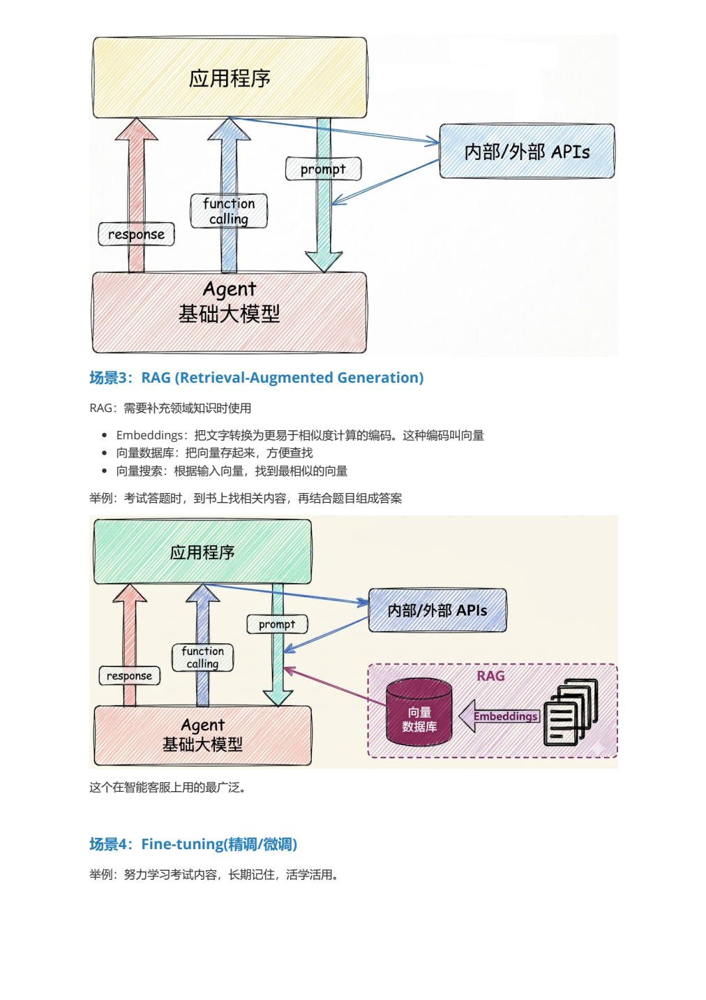


### 如何选择技术路线？

课程给出的基本判断顺序是：

~~~text
准备测试数据
      ↓
用 Prompt 验证应用可行性
      ↓
是否需要补充领域知识？ ── 是 → RAG
      ↓ 否
是否需要对接其它系统？ ── 是 → Function Calling / Tools / Agent
      ↓ 否
是否值得通过历史数据改变模型行为？ ── 是 → Fine-tuning
      ↓ 否
    交付
~~~

这不是绝对的技术顺序，而是一种先用低成本方案验证问题，再逐步增加系统复杂度的工程思路。

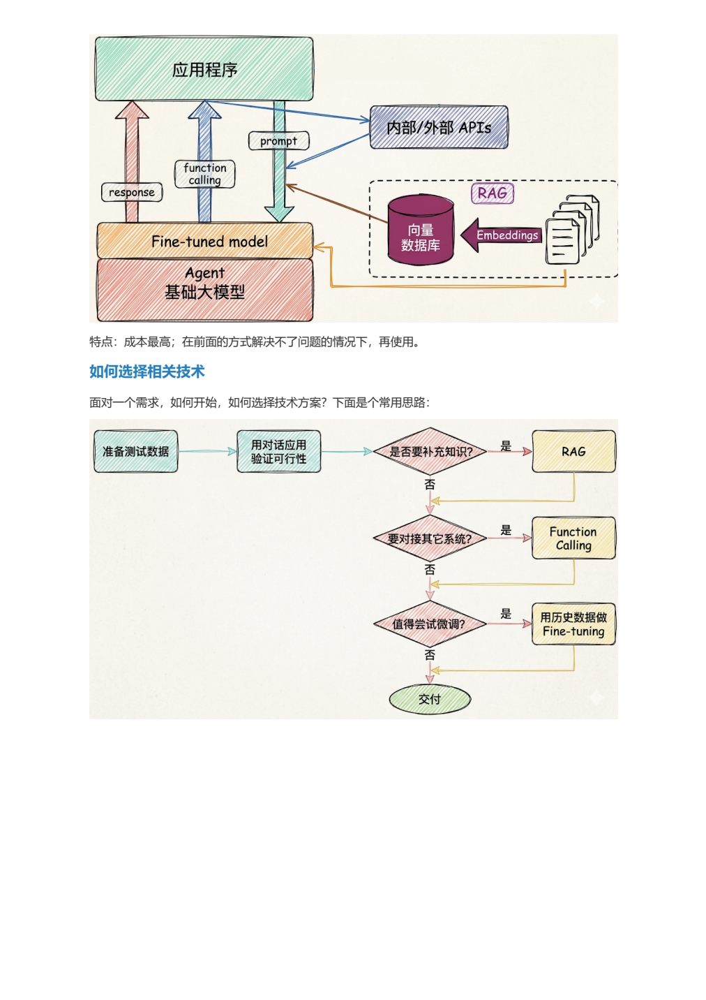


## 复习：从需求走到 LangChain

| 需求 | 优先理解的能力 | 典型组件 |
| --- | --- | --- |
| 直接问答 | 模型调用和 Prompt | Model、Prompt、Message |
| 接入私有文档 | 检索增强 | Loader、Splitter、Embedding、Retriever |
| 调用外部系统 | 工具和执行 | Tool、Function Calling、Agent |
| 多轮上下文 | 状态和记忆 | Message history、Checkpointer、Store |
| 多步骤和循环 | 显式编排 | LangGraph |
| 线上调试和评测 | 追踪与质量控制 | LangSmith |

**面试提示**：LangChain 负责把模型能力和应用组件连接起来；RAG 是补充外部知识，Function Calling 是连接外部动作，Fine-tuning 是改变模型参数或行为。三者解决的问题不同，不能互相替代。
